# Support Vector Machines nos dados covtype de LIBSVM

Iremos treinar os dados para classificação binária usando os dados `covtype` da biblioteca [LIBSVM](https://www.csie.ntu.edu.tw/~cjlin/libsvm/). Veja também [Kaggle-LIBSVM](https://www.kaggle.com/code/tanmayunhale/libsvm-liblinear).

Desta vez, iremos usar o algoritmo SVM:

$$
\min_{w\in {\mathbb R}^{d\times1}} f_n(w)=\frac{1}{n}\sum_{i=1}^n \max\{0,1-y_i(x_i^\top w)\} + \frac{\gamma}{2}\|w\|^2,
$$

onde $x_i\in {\mathbb R}^{d\times1}$, $y_i\in \{-1, 1\}$. Uma diferença em relação à regressão logística é que a função custo não é diferenciável. Um subgradiente num ponto $w$ é dado por

$$
g_n(w) = -\frac{1}{n}\sum_{i=1}^n\mathbb{1}_{\{y_i(x_i^\top w)<1\}}y_ix_i + \gamma w.
$$

Portanto, poderíamos usar o método subgradiente. Neste projeto, entretanto, iremos considerar o caso em que $n$ é muito grande de modo que avaliar $f(w)$ ou $g(w)$ é muito custoso. Note que $f(w)$ é a média empírica de 

$$
F_i(w) := \max\{0,1-y_i(x_i^\top w)\} + \frac{\gamma}{2}\|w\|^2.
$$

Alternativamente iremos usar em cada iteração um único ponto da amostra e aplicar o método subgradiente estocástico com o subgradiente:

$$
G_i(w) := -\mathbb{1}_{\{y_i(x_i^\top w)<1\}}y_ix_i + \gamma w.
$$

NOTA: neste projeto os labels devem estar em $\{-1,1\}$!

In [1]:
# Importação de módulos necesserários:

import matplotlib
import numpy as np
import scipy
import seaborn as sns
import matplotlib.pyplot as plt
import numpy.linalg as la
from sklearn.datasets import load_svmlight_file
from sklearn.utils.extmath import safe_sparse_dot

In [2]:
# Lendo os dados do arquivo covtype e guardando na matriz de dados X e vetor de labels y:

data = load_svmlight_file('covtype.bz2')
X, y = data[0].toarray(), data[1]
if (np.unique(y) == [1, 2]).all():
    # Devemos garantir que os labels estão em {-1, 1}
    y[y==1.] = -1
    y[y==2.] = 1
    
n, d = X.shape # tamanho da amostra, número de features    

In [3]:
X.shape

(581012, 54)

# Exercício 1: Funções auxiliares

1. Construa uma função `f(w, l2, m)` que toma o iterado `w` e a penalização $\gamma$ (=`l2`) e retorna o valor funcional $f_{m}(w)$ para algum $m\in[n]$.
2. Construa uma função `G(w, i, l2)` toma o iterado `w`, os dados $(x_i,y_i)$ e a penalização $\gamma$ (=`l2`) e retorna o subgradiente $G_i(w)$.
3. Construa uma função `g(w, l2, m)` que toma o iterado `w` e a penalização $\gamma$ (=`l2`) e retorna o subgradiente  $g_{m}(w)$ para algum $m\in[n]$ --- isto é, a média de $m$ subgradientes.
4. Construa uma função `gB(w, l2, B)` que toma o iterado `w` e a penalização $\gamma$ (=`l2`) e retorna o gradiente  $g_{B}(w)=\frac{1}{B}\sum_{i\in I_B}G_i(w)$ para algum $B\in[n]$ onde $I_B\subset[n]$ é escolhido aleatoriamente/uniformente. 

In [4]:
#Escreva o código aqui
rng = np.random.default_rng(0)

def f(w, l2, m):
    a = X[:m] @ w
    z = y[:m] * a
    return np.mean(np.maximum(0, 1-z)) + (l2/2) * w @ w

def G(w, i, l2):
    a = X[i] @ w
    z = y[i] * a
    return l2*w - (y[i]*X[i] if z < 1 else 0.0)

def g(w, l2, m):
	Xm, ym = X[:m], y[:m]
	a = Xm @ w
	z = ym * a
	return l2*w - np.mean(Xm.T@((z<1)*ym))

def gB(w, l2, B, n_samples=None):
	idx = rng.choice(n_samples or n, B, replace=False)
	Xb, yb = X[idx], y[idx]
	a = Xb @ w
	z = yb * a
	return l2*w - np.mean(Xb.T @ ((z<1)*yb))

# Inicialização

Fixaremos:

In [5]:
m = 30000
l2 = 1e+2
w0 = np.zeros(d)        # ponto inicial
it_max = 80000          # número de iterações
B = 100

# Exercício 2: Método subgradiente estocástico 1 

Iremos implementar o algoritmo [Pegasos](chrome-extension://efaidnbmnnnibpcajpcglclefindmkaj/https://www.cs.huji.ac.il/~shais/papers/ShalevSiSrCo10.pdf)

Construa uma função `sgd(f, G, w0, lr, l2, m, it_max)` que toma como entrada as funções `g()` `G()`, o ponto inicial `w0`, a regularização `l2` $(=\gamma)$, passo `lr`,  `m` e implementa o método subgradiente estocástico em `it_max` iterações iniciando de `w0`:

$$
w_{k+1} = w_k - \alpha_k G_k(w_k), 
$$

com passo $\alpha_k=\frac{lr}{\gamma k}$. **Na $k$-ézima iteração, use o ponto amostral $(x_k,y_k)$, na ordem do data set `X,y`**. Esta função deve retornar a sequência 

$$
k\mapsto f_{m}(w_k)=\frac{1}{m}\sum_{i=1}^{m} \max\{0,1-y_i(x_i^\top w_k)\} + \frac{\gamma}{2}\|w_k\|^2.
$$  

A função também deve retornar o último iterado.

In [6]:
#Escreva o código aqui
def sgd(f, G, w0, lr, l2, m, it_max):
	wk = w0.copy()
	hist = np.zeros(it_max)
	for k in range(1, it_max+1):
		wk -= (lr / (l2*k)) * G(wk, k-1, l2)
		hist[k-1] = f(wk, l2, m)

	return hist, wk

In [7]:
# gradient descent
f1 = sgd(f, G, w0, 1e-1, l2, m, it_max)

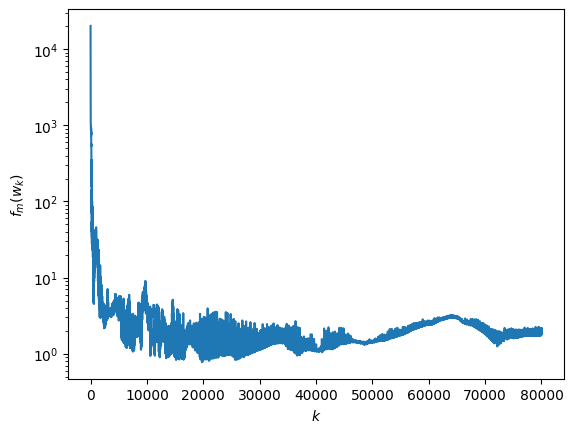

In [8]:
plt.plot(f1[0])
plt.yscale('log')
plt.ylabel(r'$f_m(w_k)$')
plt.xlabel(r'$k$')
plt.show()

# Exercício 3: Método subgradiente estocástico 2

Construa uma função `sgd2(f, G, w0, lr, l2, m, it_max)` que toma como entrada as funções `g` `G()`, o ponto inicial `w0`, a regularização `l2` $(=\gamma)$, `m` e implementa o método subgradiente estocástico em `it_max` iterações iniciando de `w0`:

$$
w_{k+1} = w_k - \alpha_k G_{i_k}(w_k),
$$

com passo $\alpha_k=\frac{lr}{\gamma k}$, onde **na $k$-ézima iteração, $i_k\in[n]$ é escolhido uniformemente ao acaso, usand o ponto amostral $(x_{i_k},y_{i_k})$**. Esta função deve retornar a sequência 

$$
k\mapsto f_{m}(w_k)=\frac{1}{m}\sum_{i=1}^{m} \max\{0,1-y_i(x_i^\top w_k)\} + \frac{\gamma}{2}\|w_k\|^2.
$$ 

A função também deve retornar o último iterado.

In [9]:
#Escreva o código aqui
def sgd2(f, G, w0, lr, l2, m, it_max, n_samples=None):
	wk = w0.copy()
	hist = np.zeros(it_max)
	for k in range(1, it_max):
		ik = rng.choice(n_samples or n)
		wk -= (lr / (l2*k)) * G(wk, ik, l2)
		hist[k-1] = f(wk, l2, m)

	return hist, wk

In [10]:
# gradient descent
f2 = sgd2(f, G, w0, 1e-1, l2, m, it_max)

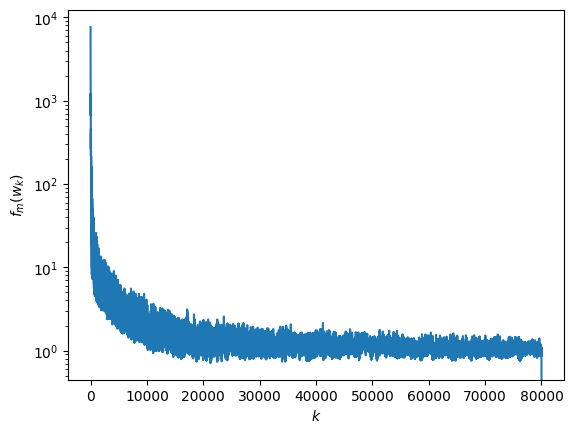

In [11]:
plt.plot(f2[0])
plt.yscale('log')
plt.ylabel(r'$f_m(w_k)$')
plt.xlabel(r'$k$')
plt.show()

# Exercício 4: Método subgradiente estocástico 3

Construa agora função `sgd3(f, gB, w0, lr, l2, m, B, it_max)` que toma como entrada as funções `f` `gB()`, o ponto inicial `w0`, a regularização `l2` $(=\gamma)$ e implementa o método subgradiente estocástico com mini-batch size `B` em `it_max` iterações iniciando de `w0`:

$$
w_{k+1} = w_k - \alpha_k \cdot\frac{1}{B}\sum_{i\in B_k}G_{i}(w_k),
$$

onde **na $k$-ézima iteração, $B_k\subset\in[n]$ é escolhido uniformemente ao acaso, usando o mini-batch $\{(x_{i},y_{i})\}_{i\in B_k}$**. Esta função deve retornar a sequência 

$$
k\mapsto f_{\text{it max}}(w_k)=\frac{1}{\text{it max}}\sum_{i=1}^{\text{it max}} \max\{0,1-y_i(x_i^\top w_k)\} + \frac{\gamma}{2}\|w_k\|^2.
$$ 

A função também deve retornar o último iterado. Implemente com passo $\alpha_k=\frac{lr}{\gamma k}$.  

In [12]:
#Escreva o código aqui
def sgd3(f, gb, w0, lr, l2, m, B, it_max, n_samples=None):
	wk = w0.copy()
	hist = np.zeros(it_max)
	for k in range(1, it_max+1):
		wk -= (lr / (l2*k)) * gb(wk, l2, B, n_samples)
		hist[k-1] = f(wk, l2, m)

	return hist, wk

In [13]:
f3 = sgd3(f, gB, w0, 1e-1, l2, m, B, it_max)

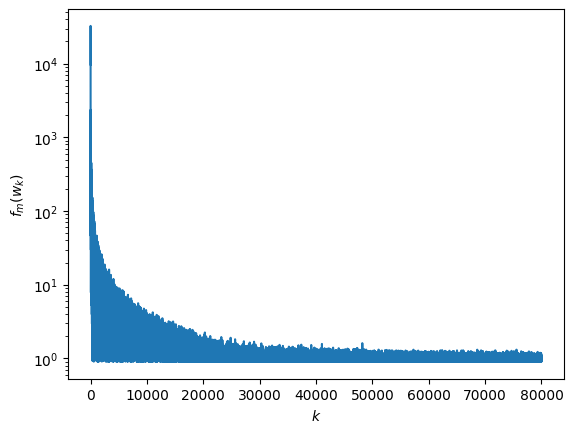

In [14]:
plt.plot(f3[0])
plt.yscale('log')
plt.ylabel(r'$f_m(w_k)$')
plt.xlabel(r'$k$')
plt.show()

# Exercício 5: 

Implemente num mesmo gráfico os erros $f_{\text{it_max}}(w_k)$ de cada método em função no número de iterações.

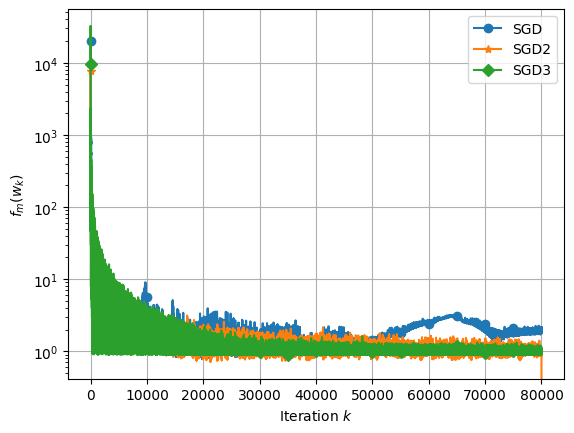

In [15]:
plt.plot(f1[0], label='SGD', marker='o', markevery=5000)
plt.plot(f2[0], label='SGD2', marker='*', markevery=5000)
plt.plot(f3[0], label='SGD3', marker='D', markevery=5000)
plt.yscale('log')
plt.ylabel(r'$f_m(w_k)$')
plt.xlabel(r'Iteration $k$')
plt.legend()
plt.grid(True)
plt.show()

In [16]:
#Escreva o código aqui

# Exercício 6:

Nos exercícios anteriores, usamos os $m$ primeiros pontos de dados `y[:m], X[:m]` para plotar a sequência $k\mapsto f_m(w_k)$. Isto não é ideal já que usamos também todo ou parte de `y[:m], X[:m]` para construir a sequência de iterados $k\mapsto w_k$. Refaça os 3 exercícios anteriores mas antes dividindo o data set `y, X` em duas partes 
`y[n-m:], X[n-m:]` e `y[:n-m], X[:n-m]`. Use o dataset `y[:n-m], X[:n-m]` de tamanho `n-m` para construir a sequência de iterados $k\mapsto w_k$ e `y[n-m:], X[n-m:]` de tamanho `m` para computar $f_m(w)$ para cada iterado $w$. Plote os 3 gráficos correspondentes e depois o gráfico com os 6 métodos diferentes. Você nota alguma diferença?

In [17]:
#Escreva o código aqui
X_train, X_test = X[:n-m], X[n-m:]
y_train, y_test = y[:n-m], y[n-m:]

def fm(w, l2, m):
      a = X_test @ w
      z = y_test * a
      return np.mean(np.maximum(0, 1-z)) + (l2/2) * w @ w

def Gm(w, i, l2):
    a = X_train[i] @ w
    z = y_train[i] * a
    return l2*w - (y_train[i]*X_train[i] if z < 1 else 0.0)

def gm(w, l2, m):
	Xm, ym = X_train[:m], y_train[:m]
	a = Xm @ w
	z = ym * a
	return l2*w - np.mean(Xm.T@((z<1)*ym))

def gBm(w, l2, B, n_samples=None):
	idx = rng.choice(n_samples or n, B, replace=False)
	Xb, yb = X[idx], y[idx]
	a = Xb @ w
	z = yb * a
	return l2*w - np.mean(Xb.T @ ((z<1)*yb))

In [18]:
#Escreva o código aqui
f1m = sgd(fm, Gm, w0, 1e-1, l2, m, it_max)

In [19]:
#Escreva o código aqui
f2m = sgd2(fm, Gm, w0, 1e-1, l2, m, it_max, n-m)

In [20]:
f3m = sgd3(fm, gBm, w0, 1e-1, l2, m, B, it_max, n-m)

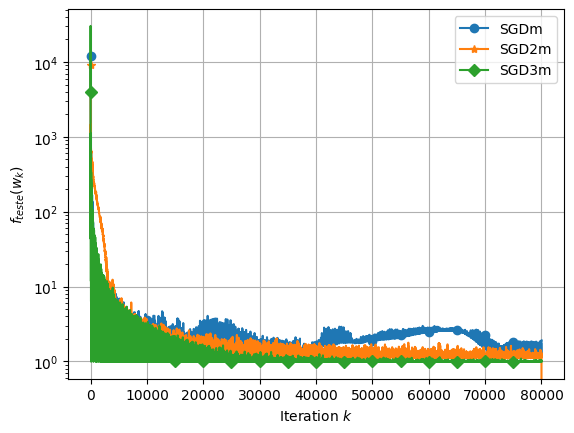

In [21]:
plt.plot(f1m[0], label='SGDm', marker='o', markevery=5000)
plt.plot(f2m[0], label='SGD2m', marker='*', markevery=5000)
plt.plot(f3m[0], label='SGD3m', marker='D', markevery=5000)
plt.yscale('log')
plt.ylabel(r'$f_{teste}(w_k)$')
plt.xlabel(r'Iteration $k$')
plt.legend()
plt.grid(True)
plt.show()

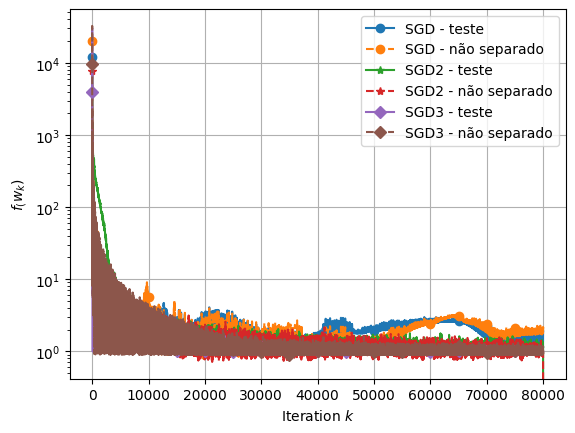

In [22]:
plt.plot(f1m[0], label='SGD - teste', marker='o', markevery=5000)
plt.plot(f1[0], label='SGD - não separado', ls='--', marker='o', markevery=5000)
plt.plot(f2m[0], label='SGD2 - teste', marker='*', markevery=5000)
plt.plot(f2[0], label='SGD2 - não separado', ls='--', marker='*', markevery=5000)
plt.plot(f3m[0], label='SGD3 - teste', marker='D', markevery=5000)
plt.plot(f3[0], label='SGD3 - não separado', ls='--', marker='D', markevery=5000)
plt.yscale('log')
plt.ylabel(r'$f_(w_k)$')
plt.xlabel(r'Iteration $k$')
plt.legend()
plt.grid(True)
plt.show()

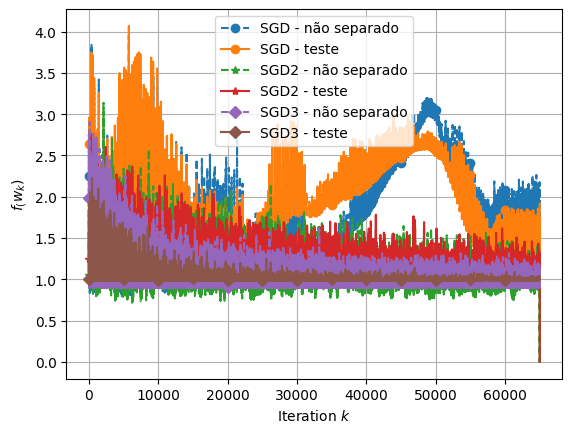

In [23]:

plt.plot(f1[0][15000:], label='SGD - não separado', ls='--', marker='o', markevery=5000)
plt.plot(f1m[0][15000:], label='SGD - teste', marker='o', markevery=5000)
plt.plot(f2[0][15000:], label='SGD2 - não separado', ls='--', marker='*', markevery=5000)
plt.plot(f2m[0][15000:], label='SGD2 - teste', marker='*', markevery=5000)
plt.plot(f3[0][15000:], label='SGD3 - não separado', ls='--', marker='D', markevery=5000)
plt.plot(f3m[0][15000:], label='SGD3 - teste', marker='D', markevery=5000)

#plt.yscale('log')
plt.ylabel(r'$f_(w_k)$')
plt.xlabel(r'Iteration $k$')
plt.legend()
plt.grid(True)
plt.show()

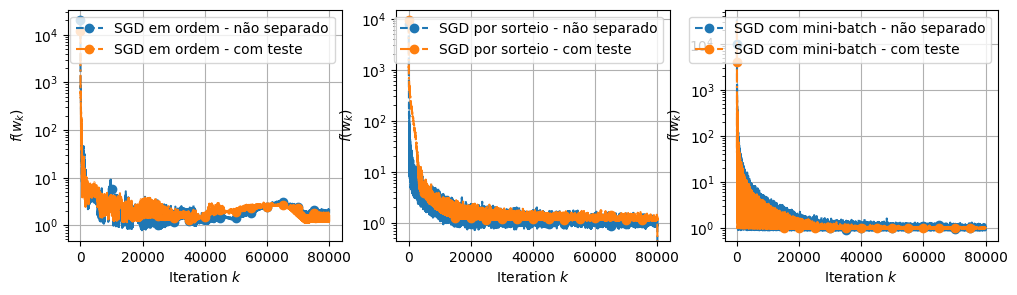

In [26]:
pares = [
    (f1, f1m, 'em ordem'),
    (f2, f2m, 'por sorteio'),
    (f3, f3m, 'com mini-batch')
]

fig, axs = plt.subplots(1, 3, figsize=(12, 3))

for i in range(3):
    axs[i].plot(pares[i][0][0], label=f'SGD {pares[i][2]} - não separado', ls='--', marker='o', markevery=5000)
    axs[i].plot(pares[i][1][0], label=f'SGD {pares[i][2]} - com teste', ls='-.', marker='o', markevery=5000)
    axs[i].set_yscale('log')
    axs[i].set_xlabel(r'Iteration $k$')
    axs[i].set_ylabel(r'$f(w_k)$')
    axs[i].grid(True)
    axs[i].legend()

plt.show()

Nos métodos sorteados, a implementação inicial usa dos dados de teste para realizar o treinamento, de modo que o resultado da avaliação apresente um valor menor. No sgd em ordem, são usadas as 80k primeiras linhas para o treino e as 30k primeiras linhas para o teste, de modo que a sobreposição seja bastante grande na implementação inicial, enquanto é inexistente na segunda.
Entretanto, também vale notar que que tanto o método sgd em ordem quanto o sgd com sorteio usam apenas 80k pontos para treinamento, e como o arquivo (>500 mil de linhas) não está embaralhado, pode existir um viés causado por essa única exploração. 
Apesar desses ponto, se mantém o que foi observado na primeira parte: mini batch obtém um resultado melhor que sortei, o qual, por sua vez, obtém um resultado melhor que a passagem em ordem.